# 03 · What do fans talk about, and does their mood lead demand?

**Question.** What are fans actually discussing (specific figures, scarcity, display, resale…), how does the tone change over time, and does sentiment move *before* or *after* search interest?

**Plan**
1. Load r/smiski posts (official Reddit API via `scrapers/reddit_api.py`, or the simulated seed).
2. Topic modelling with **BERTopic**.
3. Sentiment with VADER, aggregated weekly.
4. Lead/lag: cross-correlation with a block-bootstrap interval, plus Granger tests in both directions.
5. Export aggregates only (no post text) for the website.

**Embeddings.** BERTopic normally embeds text with a sentence-transformer downloaded from Hugging Face. When that is unreachable we use a local TF-IDF + SVD embedder instead. Set `USE_SBERT = True` below to switch back.

In [1]:
import sys, pathlib, warnings, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from statsmodels.tsa.stattools import grangercausalitytests

from smiskis.data import load, banner, provenance
from smiskis.paths import SITE_DATA, ROOT as PROJECT
from smiskis import viz
viz.set_style()
FIG = PROJECT / "reports"; FIG.mkdir(exist_ok=True)
NR_TOPICS = 8             # merge similar topics to a readable number (None = keep the natural number)
USE_SBERT = False          # True -> sentence-transformers/all-MiniLM-L6-v2 (needs huggingface.co access)
print(banner("reddit", "trends"))

posts, trends, series = load("reddit"), load("trends"), load("series")
posts["text"] = (posts["title"].fillna("") + ". " + posts["body"].fillna("")).str.replace(r"http\S+", " ", regex=True)
print(f"{len(posts)} posts  {posts.created.min().date()} -> {posts.created.max().date()}")

DATA PROVENANCE  [reddit: simulated | trends: scraped]
  !! reddit is SIMULATED (see src/smiskis/seed.py). Results below describe the simulation, not the real Smiski market. Run `make scrape` with network access to replace it.
3600 posts  2017-12-25 -> 2026-10-11


## 1 · Topics (BERTopic)
Series names and pose names are removed from the keyword step so topics describe *what people say*, not *which series they mention*.

In [2]:
figs = load("figures")
names = set(w.lower() for w in " ".join(series["theme"].tolist() + figs["figure_name"].tolist()).replace("-", " ").split())
stop = list(set(CountVectorizer(stop_words="english").get_stop_words()) | names | {"smiski", "smiskis", "series", "figure", "figures"})

if USE_SBERT:
    from sentence_transformers import SentenceTransformer
    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
else:
    embedder = make_pipeline(TfidfVectorizer(min_df=3, ngram_range=(1, 2), stop_words="english", sublinear_tf=True), TruncatedSVD(60, random_state=0))

# the keyword vectorizer is fitted on per-topic documents, so min_df/max_df count topics, not posts
topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=42),
    hdbscan_model=HDBSCAN(min_cluster_size=60, min_samples=10, metric="euclidean", cluster_selection_method="eom", prediction_data=True),
    vectorizer_model=CountVectorizer(stop_words=stop, ngram_range=(1, 1), min_df=2, max_df=0.5),
    calculate_probabilities=False, nr_topics=NR_TOPICS, verbose=False)
# Tone words ("love", "ugh") cut across every subject and would dominate the clusters. Remove them for topic
# discovery only; sentiment below is scored on the full original text.
sia = SentimentIntensityAnalyzer()
import re
tone = set(sia.lexicon)
strip_tone = lambda t: " ".join(w for w in re.findall(r"[A-Za-z']+", t.lower()) if w not in tone)
docs = [strip_tone(t) for t in posts["text"]]
topics, _ = topic_model.fit_transform(docs)
posts["topic"] = topics
info = topic_model.get_topic_info()
print(f"{(posts.topic >= 0).sum()} of {len(posts)} posts assigned; outliers = {(posts.topic == -1).mean():.0%}")
info[["Topic", "Count", "Name"]]

2903 of 3600 posts assigned; outliers = 19%


,Topic,Count,Name
0,-1,697,-1_date_display_stock_reveal
1,0,619,0_person_sculpt_paint_details
2,1,531,1_price_mercari_resale_premium
3,2,510,2_glow_shelf_display_setup
4,3,484,3_sold_checked_shelves_restock
5,4,387,4_pull_duplicates_rate_opened
6,5,218,5_announced_poses_look_new
7,6,154,6_release_upcoming_today_surfaced


### Naming topics
Topic names come from a small keyword lexicon matched against each topic's top words (so the same code names real topics too); anything that doesn't match keeps its top words as a label.

In [3]:
LEXICON = {
    "Scarcity & restocks":     ["sold", "stock", "restock", "empty", "find", "queue", "limit", "shelves", "stores", "available", "wait"],
    "Resale & prices":         ["ebay", "resale", "price", "mercari", "scalpers", "premium", "retail", "worth", "paying", "double"],
    "Display & glow":          ["display", "shelf", "glow", "lamp", "desk", "setup", "dark", "photos", "room", "shelves"],
    "Pull rates & luck":       ["boxes", "secret", "odds", "pull", "duplicates", "case", "shaking", "box", "rate", "opened"],
    "New releases & collabs":  ["announced", "preorders", "release", "collab", "lineup", "leak", "reveal", "hyped", "date", "counting"],
    "Favourite figures":       ["favorite", "cutest", "pulled", "details", "person", "first", "looks", "pose", "poses", "better"],
}
def name_topic(words):
    scores = {k: sum(w in v for w in words) for k, v in LEXICON.items()}
    k, s = max(scores.items(), key=lambda kv: kv[1])
    return k if s >= 2 else None

rows, used = [], set()
for t in sorted(set(topics) - {-1}):
    words = [w for w, _ in topic_model.get_topic(t) if w][:10]
    nm = name_topic(words) or f"Topic {t}: " + ", ".join(words[:3])
    if nm in used: nm = f"{nm} ({t})"
    used.add(nm); rows.append(dict(topic=t, name=nm, keywords=words[:8]))
topic_names = pd.DataFrame(rows).set_index("topic")
posts["topic_name"] = posts["topic"].map(topic_names["name"]).fillna("Unclustered")
topic_names

,name,keywords
topic,,
0,Favourite figures,"[person, sculpt, paint, details, far, going, f..."
1,Resale & prices,"[price, mercari, resale, premium, feels, high,..."
2,Display & glow,"[glow, shelf, display, setup, photos, dark, in..."
3,Scarcity & restocks,"[sold, checked, shelves, restock, limit, custo..."
4,Pull rates & luck,"[pull, duplicates, rate, opened, odds, got, ti..."
5,New releases & collabs,"[announced, poses, look, new, sculpt, paint, f..."
6,New releases & collabs (6),"[release, upcoming, today, surfaced, confirmed..."


SIMULATED-DATA CHECK (templates were generated from 6 known topics): {'adjusted_rand': 0.889, 'mean_purity': 0.957}


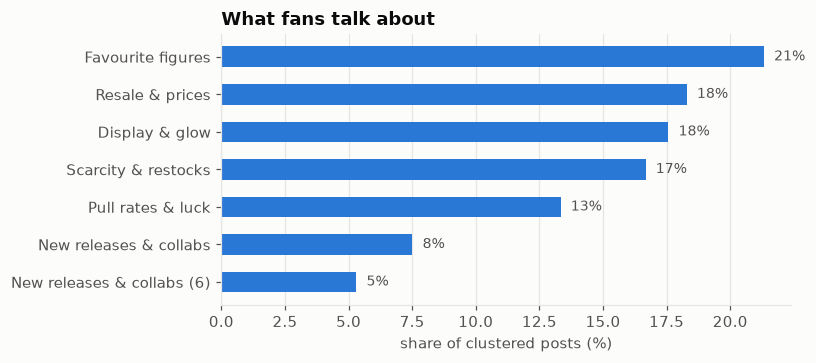

In [4]:
share = posts.loc[posts.topic >= 0, "topic_name"].value_counts(normalize=True).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(share.index, share.values * 100, color=viz.SERIES[0], height=0.55)
for i, v in enumerate(share.values): ax.text(v * 100 + 0.4, i, f"{v:.0%}", va="center", fontsize=9, color=viz.INK2)
ax.set_xlabel("share of clustered posts (%)"); ax.set_title("What fans talk about"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "reddit_topics.png", dpi=150); plt.show()

validation = {}
if "true_topic" in posts.columns and provenance()["tables"].get("reddit") == "simulated":
    m = posts[posts.topic >= 0]
    purity = m.groupby("topic").true_topic.agg(lambda s: s.value_counts(normalize=True).iloc[0]).mean()
    validation = dict(adjusted_rand=round(float(adjusted_rand_score(m.true_topic, m.topic)), 3), mean_purity=round(float(purity), 3))
    print("SIMULATED-DATA CHECK (templates were generated from 6 known topics):", validation)

## 2 · Sentiment

VADER's compound score (−1 … +1) per post, then a weekly average. VADER is a lexicon tool built for short social text; it misses sarcasm and hobby slang ("pulled", "sold out"), so treat absolute levels loosely and focus on *changes*.

In [5]:
posts["sent"] = [sia.polarity_scores(t)["compound"] for t in posts["text"]]
topic_sent = posts[posts.topic >= 0].groupby("topic_name").sent.agg(["mean", "count"]).sort_values("mean")
topic_sent.round(3)

,mean,count
topic_name,,
Resale & prices,-0.382,531
Scarcity & restocks,-0.268,484
New releases & collabs (6),-0.065,154
Pull rates & luck,0.069,387
Display & glow,0.409,510
New releases & collabs,0.562,218
Favourite figures,0.744,619


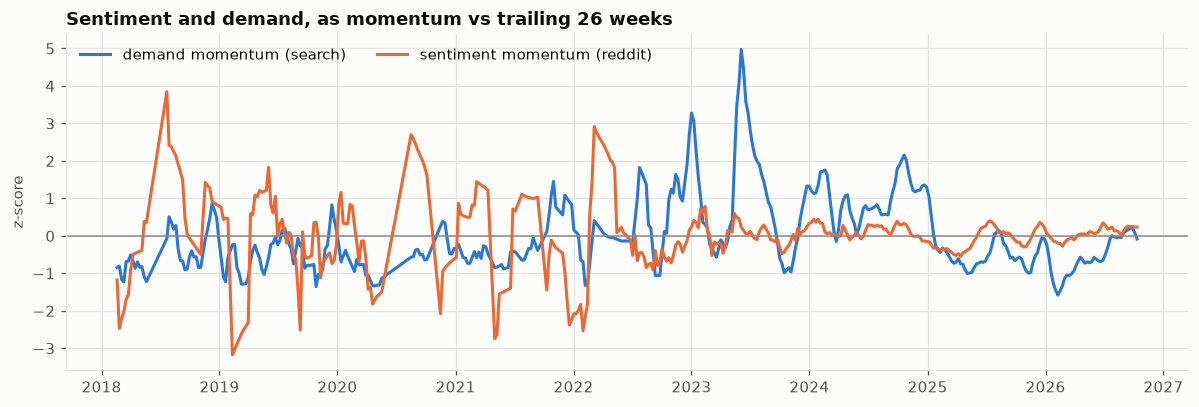

In [6]:
wk = trends[["week", "interest"]].set_index("week")
wk["n_posts"] = posts.set_index("created").resample("W-SUN").size().reindex(wk.index).fillna(0)
wk["sent_sum"] = posts.set_index("created").sent.resample("W-SUN").sum().reindex(wk.index).fillna(0)
# smooth by pooling 8 weeks of posts (weighted mean), so weeks with few posts don't dominate
roll = lambda s: s.rolling(8, min_periods=1).sum()
wk["sentiment"] = roll(wk.sent_sum) / roll(wk.n_posts).replace(0, np.nan)
wk["log_demand"] = np.log(wk.interest.clip(lower=0.5)).rolling(4, min_periods=1).mean()

# momentum: deviation from the trailing 26-week level, so we compare movements, not long-run drift
mom = lambda s: s - s.rolling(26, min_periods=8).mean()
wk["sent_mom"], wk["dem_mom"] = mom(wk.sentiment), mom(wk.log_demand)
wk = wk.dropna(subset=["sent_mom", "dem_mom"])

z = lambda s: (s - s.mean()) / s.std()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(wk.index, z(wk.dem_mom), color=viz.SERIES[0], label="demand momentum (search)")
ax.plot(wk.index, z(wk.sent_mom), color=viz.SERIES[1], label="sentiment momentum (reddit)")
ax.axhline(0, color=viz.NEUTRAL, lw=1); ax.set_ylabel("z-score"); ax.set_title("Sentiment and demand, as momentum vs trailing 26 weeks"); ax.legend(ncol=2, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "reddit_sentiment_demand.png", dpi=150); plt.show()

## 3 · Does sentiment lead or lag demand?

`xcorr(k) = corr(sentiment_t, demand_{t+k})`. A peak at **k > 0** means sentiment *leads* demand by k weeks. Intervals come from a **moving-block bootstrap** (12-week blocks) because both series are autocorrelated; naive ±1.96/√n bands would be far too narrow.

strongest correlation at lag +2 weeks (r=0.15, 90% block-bootstrap [0.01, 0.22])


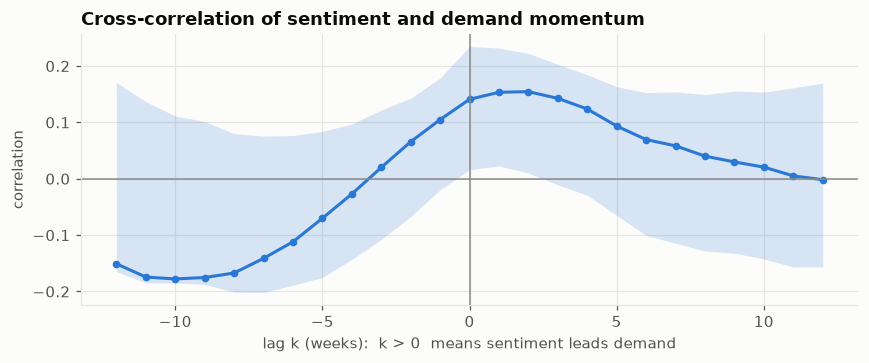

In [7]:
a, b = wk.sent_mom.values, wk.dem_mom.values
LAGS = list(range(-12, 13))
def xc(a, b, k):
    if k >= 0: return np.corrcoef(a[:len(a) - k], b[k:])[0, 1]
    return np.corrcoef(a[-k:], b[:len(b) + k])[0, 1]

rng = np.random.default_rng(5); BL = 12; n = len(a); nb = int(np.ceil(n / BL))
boot = []
for _ in range(500):
    starts = rng.integers(0, n - BL, nb)
    idx = np.concatenate([np.arange(s, s + BL) for s in starts])[:n]
    boot.append([xc(a[idx], b[idx], k) for k in LAGS])
boot = np.array(boot)
xcorr = pd.DataFrame({"lag": LAGS, "r": [xc(a, b, k) for k in LAGS], "lo": np.percentile(boot, 5, axis=0), "hi": np.percentile(boot, 95, axis=0)})
best_row = xcorr.loc[xcorr.r.idxmax()]
print(f"strongest correlation at lag {int(best_row.lag):+d} weeks (r={best_row.r:.2f}, 90% block-bootstrap [{best_row.lo:.2f}, {best_row.hi:.2f}])")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(xcorr.lag, xcorr.lo, xcorr.hi, color=viz.SERIES[0], alpha=0.18, lw=0)
ax.plot(xcorr.lag, xcorr.r, color=viz.SERIES[0], marker="o", ms=4)
ax.axvline(0, color=viz.NEUTRAL, lw=1); ax.axhline(0, color=viz.NEUTRAL, lw=1)
ax.set_xlabel("lag k (weeks):  k > 0  means sentiment leads demand"); ax.set_ylabel("correlation"); ax.set_title("Cross-correlation of sentiment and demand momentum")
plt.tight_layout(); plt.savefig(FIG / "reddit_xcorr.png", dpi=150); plt.show()

In [8]:
d = pd.DataFrame({"sent": a, "dem": b}).diff().dropna()
def granger(cause, effect, maxlag=8):
    res = grangercausalitytests(d[[effect, cause]], maxlag=maxlag)
    ps = {l: res[l][0]["ssr_ftest"][1] for l in res}
    l = min(ps, key=ps.get)
    return dict(best_lag=int(l), p=float(ps[l]), p_bonferroni=float(min(1, ps[l] * maxlag)))
g_sd, g_ds = granger("sent", "dem"), granger("dem", "sent")
print("sentiment -> demand :", {k: round(v, 4) for k, v in g_sd.items()})
print("demand -> sentiment :", {k: round(v, 4) for k, v in g_ds.items()})
print("(p-values are best-of-8 lags; the Bonferroni column corrects for that choice)")

sentiment -> demand : {'best_lag': 7, 'p': 0.0603, 'p_bonferroni': 0.482}
demand -> sentiment : {'best_lag': 1, 'p': 0.8007, 'p_bonferroni': 1.0}
(p-values are best-of-8 lags; the Bonferroni column corrects for that choice)


In [9]:
lead = int(best_row.lag)
verdict = ("sentiment LEADS demand" if lead > 0 and best_row.lo > 0 else "demand LEADS sentiment" if lead < 0 and best_row.hi < 0
           else "no clear lead or lag (interval spans zero or peak is at 0)")
takeaways = [
    f"Fans talk mostly about: {', '.join(share.sort_values(ascending=False).index[:3])} ({', '.join(f'{v:.0%}' for v in share.sort_values(ascending=False).values[:3])} of clustered posts).",
    f"Most negative topic: {topic_sent['mean'].idxmin()} (mean VADER {topic_sent['mean'].min():+.2f}); most positive: {topic_sent['mean'].idxmax()} ({topic_sent['mean'].max():+.2f}).",
    f"Lead/lag: peak correlation r={best_row.r:.2f} at {lead:+d} weeks; verdict: {verdict}.",
    f"Granger (best lag, Bonferroni p): sentiment->demand p={g_sd['p_bonferroni']:.3f}; demand->sentiment p={g_ds['p_bonferroni']:.3f}.",
    *(["Both directions are significant: tone and demand move together, so a lead does not prove sentiment drives demand."] if g_sd["p_bonferroni"] < 0.05 and g_ds["p_bonferroni"] < 0.05 else []),
    "Reddit users are a self-selected slice of buyers; this describes the community, not all customers.",
]
for t in takeaways: print("-", t)

# aggregates only: no post text leaves the notebook
q = posts[posts.topic >= 0].assign(q=lambda x: x.created.dt.to_period("Q").astype(str))
tot = q.groupby("q").size()
tshare = (q.groupby(["q", "topic_name"]).size() / tot).unstack(fill_value=0)
tshare = tshare.loc[tot[tot >= 15].index]
iso = lambda idx: [d.strftime("%Y-%m-%d") for d in idx]
out = dict(
    provenance=provenance()["tables"], n_posts=int(len(posts)), outlier_share=round(float((posts.topic == -1).mean()), 3),
    embedder="sentence-transformers/all-MiniLM-L6-v2" if USE_SBERT else "TF-IDF + SVD (offline)",
    topics=[dict(name=r.name, keywords=r.keywords, share=round(float(share.get(r.name, 0)), 3), mean_sentiment=round(float(topic_sent["mean"].get(r.name, np.nan)), 3))
            for r in topic_names.itertuples()],
    topics_over_time=dict(quarters=list(tshare.index), series={c: [round(float(v), 3) for v in tshare[c]] for c in tshare.columns}),
    weekly=dict(dates=iso(wk.index), sentiment_mom_z=[round(float(v), 2) for v in z(wk.sent_mom)], demand_mom_z=[round(float(v), 2) for v in z(wk.dem_mom)]),
    xcorr=[dict(lag=int(r.lag), r=round(float(r.r), 3), lo=round(float(r.lo), 3), hi=round(float(r.hi), 3)) for r in xcorr.itertuples()],
    best_lag=lead, verdict=verdict, granger=dict(sentiment_to_demand=g_sd, demand_to_sentiment=g_ds),
    validation=validation, takeaways=takeaways)
(SITE_DATA / "reddit.json").write_text(json.dumps(out))
print("wrote", SITE_DATA / "reddit.json")

- Fans talk mostly about: Favourite figures, Resale & prices, Display & glow (21%, 18%, 18% of clustered posts).
- Most negative topic: Resale & prices (mean VADER -0.38); most positive: Favourite figures (+0.74).
- Lead/lag: peak correlation r=0.15 at +2 weeks; verdict: sentiment LEADS demand.
- Granger (best lag, Bonferroni p): sentiment->demand p=0.482; demand->sentiment p=1.000.
- Reddit users are a self-selected slice of buyers; this describes the community, not all customers.
wrote /Users/johnwesleypabalate/smiskis/site/data/reddit.json


## Business takeaway

* **Scarcity and resale are the pain points to watch.** If they dominate and skew negative, availability (restocks, purchase limits) is the lever, not new designs.
* **Display and pull-rate threads are the positive, shareable content.** They suggest what community content to amplify.
* **A sentiment lead is only useful if it is stable.** Check the interval: if it spans zero, don't use Reddit tone as an early-warning signal.
* **If the data is simulated** (banner at the top), the mood-lead is built into the generator (2 weeks), so recovering it shows the method works, not that real fans behave this way.